# **Lecture 8. Relational Databases and SQL**
## **Teaching Database: Company — Employees, Departments, and Projects**

**Environment:** Google Colab · **Languages:** Python + SQL · **DBMS:** SQLite.


# **§1. Database Management Systems**

# A **database (DB)** is an organised collection of related data. A **database management system (DBMS)** is a software system for creating, storing, retrieving, modifying, and protecting data.

# A company needs to store information about departments, employees, clients, projects, and work assignments. Unconnected files containing repeated data make updates difficult: a department name has to be changed in many rows. Related tables allow this fact to be stored in one place.

| DBMS Capability | Company Example |
|---|---|
| Data abstraction | An analyst uses tables and SQL without choosing where records are stored on disk |
| Integrity | An employee cannot be assigned to a project that does not exist |
| Transactions | Several related changes are committed or rolled back together |
| Shared access | Several applications access the same database |
| Access control | Server-based DBMSs can grant different permissions to different users |
| Recovery | Backups help restore data |

# The specific mechanisms depend on the DBMS. SQLite runs without a separate server and does not have a built-in user and role system comparable to PostgreSQL.


# **§2. The Relational Model and the Company Schema**

# A **table** contains rows (records) and columns (attributes). For example, a row in `employees` describes one employee, and `last_name` stores that employee's surname.

# A **primary key (PK)** uniquely identifies a record; it may consist of one or more columns. A **foreign key (FK)** references a key in another table and maintains referential integrity. FK values may repeat. `NULL` is allowed unless prohibited by `NOT NULL`: whether a relationship is mandatory is specified separately.

# The table names and fields below match the supplied ER diagram.


### ER Diagram

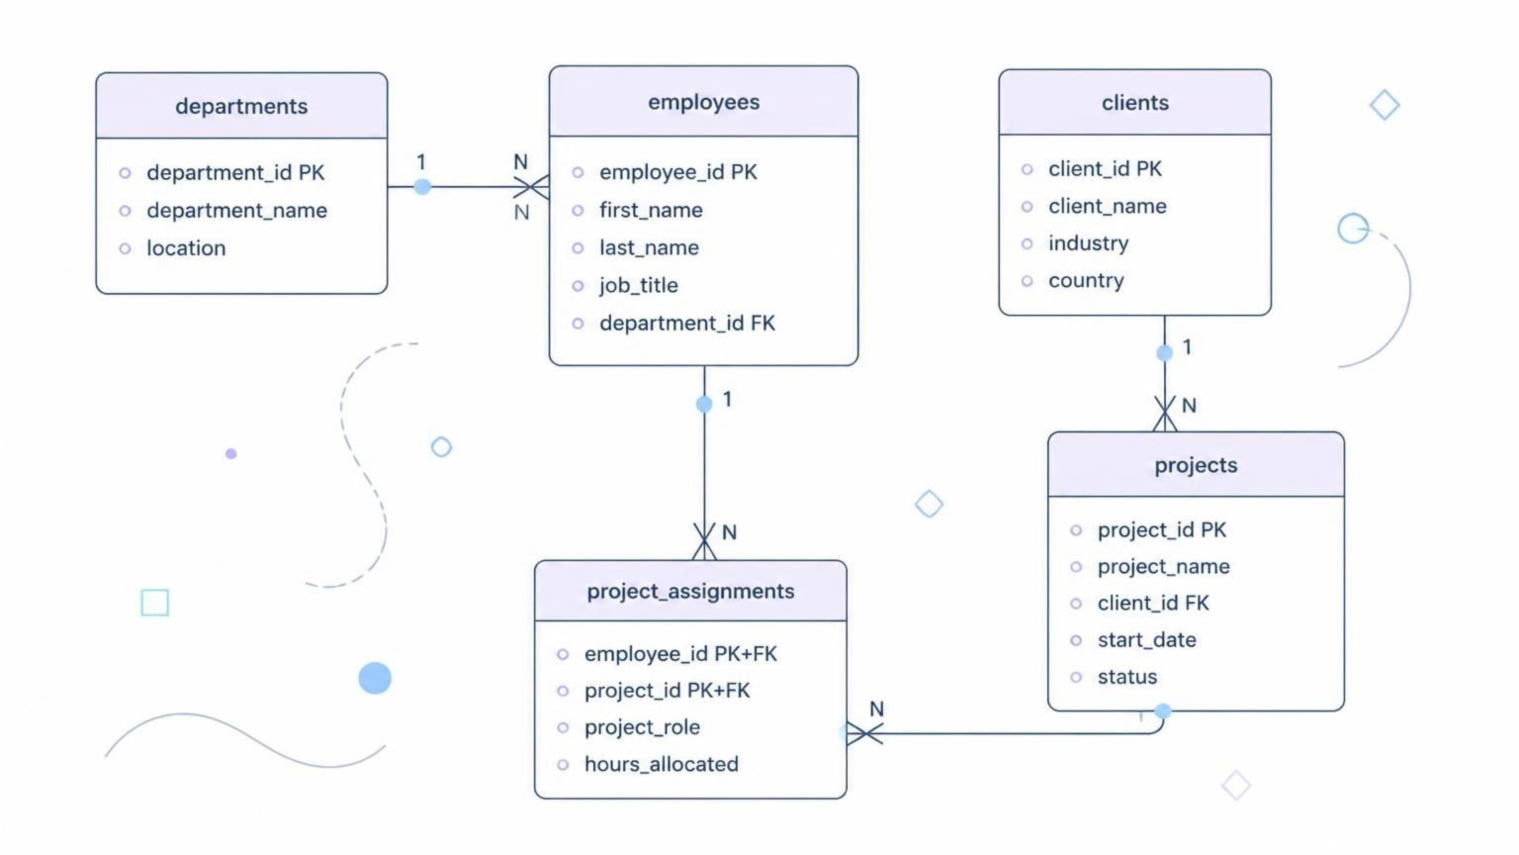


# **Table and Attribute Dictionary**

| Table | Fields | Purpose |
|---|---|---|
| `departments` | `department_id` PK, `department_name`, `location` | Company departments |
| `employees` | `employee_id` PK, `first_name`, `last_name`, `job_title`, `department_id` FK | Employees and their departments |
| `clients` | `client_id` PK, `client_name`, `industry`, `country` | Company clients |
| `projects` | `project_id` PK, `project_name`, `client_id` FK, `start_date`, `status` | Projects for clients |
| `project_assignments` | (`employee_id`, `project_id`) PK; both fields are FKs, `project_role`, `hours_allocated` | Employee participation in projects |

# `hours_allocated` is the number of hours planned for an employee **over the entire project**, rather than hours per week or actual hours worked. `project_role` is the employee's role in a particular project; it may differ from their `job_title`.

# For simplicity, each employee must belong to one department, and each project must have one client. An employee may not yet participate in any projects; a project may not yet have a team.


# **§3. SQL and SQLite**

# **SQL (Structured Query Language)** is a language for defining structures, reading data, and modifying data. `SELECT` retrieves data; SQL also includes other statements.

| Category | Main Statements | Purpose |
|---|---|---|
| Data Definition Language, DDL | `CREATE`, `ALTER`, `DROP` | Create or modify structures |
| Data Manipulation Language, DML | `INSERT`, `UPDATE`, `DELETE` | Add, modify, or delete records |
| Querying (often classified as DQL) | `SELECT` | Retrieve data |
| Transaction control | `BEGIN`, `COMMIT`, `ROLLBACK` | Commit or roll back changes |

# **SQLite** is an embedded relational DBMS. A database can be stored in a single file or in memory. The `sqlite3` module is part of the Python standard library.

# In SQLite, we use `INTEGER`, `TEXT`, and `REAL`. In this lecture, dates are stored as ISO `YYYY-MM-DD` strings: with this consistent format, string sorting matches chronological order. `NOT NULL` prohibits missing values; `CHECK` verifies a condition. `NULL` represents a missing value and is tested using `IS NULL`, rather than `= NULL`.


# **The Structure of a SELECT Query**

```sql
SELECT columns_or_expressions
FROM table_name
JOIN another_table ON join_condition
WHERE row_condition
GROUP BY grouping_columns
HAVING group_condition
ORDER BY sorting_columns
LIMIT row_count;
```

# Simplified logical processing order: `FROM/JOIN → WHERE → GROUP BY → HAVING → SELECT → DISTINCT → ORDER BY → LIMIT`. `WHERE` filters rows before grouping; `HAVING` filters the resulting groups. Without `ORDER BY`, the order of the results is not guaranteed.


# **§4. Connecting to and Creating the Database**

## 4.1. Connecting Python to SQLite

# `connect()` opens the database, `cursor()` creates a cursor, and `execute()` runs a statement. We use pandas to display results as tables. The `show()` function below simply sends SQL to SQLite and displays the result; the query itself is written in SQL.

# In SQLite, foreign key enforcement must be enabled for each connection. We enable it before starting a transaction.


In [1]:
import sqlite3
from pathlib import Path
import pandas as pd

# Close the previous connection when rerunning this cell.
if "conn" in globals():
    conn.close()

DB_PATH = Path("company.db")
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")
cursor = conn.cursor()

def show(sql, params=()):
    """Execute SELECT and display the result as a table."""
    result = pd.read_sql_query(sql, conn, params=params)
    display(result)
    return None

print("SQLite:", sqlite3.sqlite_version)
print("Foreign keys enabled:", bool(conn.execute("PRAGMA foreign_keys").fetchone()[0]))


SQLite: 3.53.1
Foreign keys enabled: True


# **4.2. Creating Five Related Tables**

# This cell **drops the five teaching tables and recreates them**. First, we drop the child tables, then the parent tables. We create them in the reverse order.

# `ON DELETE CASCADE` in the assignments table means that deleting an employee or a project also deletes the corresponding assignments. We use `RESTRICT` for a department with employees and a client with projects: such deletions are prohibited.

# `CHECK` restricts hours to non-negative values and specifies the allowed statuses. The primary key of the assignments table consists of two fields.


In [2]:
conn.executescript("""
DROP TABLE IF EXISTS project_assignments;
DROP TABLE IF EXISTS projects;
DROP TABLE IF EXISTS employees;
DROP TABLE IF EXISTS clients;
DROP TABLE IF EXISTS departments;

CREATE TABLE departments (
    department_id INTEGER PRIMARY KEY,
    department_name TEXT NOT NULL UNIQUE,
    location TEXT NOT NULL
);

CREATE TABLE employees (
    employee_id INTEGER PRIMARY KEY,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    job_title TEXT NOT NULL,
    department_id INTEGER NOT NULL,
    FOREIGN KEY (department_id) REFERENCES departments(department_id)
        ON UPDATE CASCADE ON DELETE RESTRICT
);

CREATE TABLE clients (
    client_id INTEGER PRIMARY KEY,
    client_name TEXT NOT NULL UNIQUE,
    industry TEXT NOT NULL,
    country TEXT NOT NULL
);

CREATE TABLE projects (
    project_id INTEGER PRIMARY KEY,
    project_name TEXT NOT NULL,
    client_id INTEGER NOT NULL,
    start_date TEXT NOT NULL,
    status TEXT NOT NULL CHECK (status IN ('Planned', 'Active', 'Completed')),
    FOREIGN KEY (client_id) REFERENCES clients(client_id)
        ON UPDATE CASCADE ON DELETE RESTRICT
);

CREATE TABLE project_assignments (
    employee_id INTEGER NOT NULL,
    project_id INTEGER NOT NULL,
    project_role TEXT NOT NULL,
    hours_allocated REAL NOT NULL
        CHECK (typeof(hours_allocated) IN ('integer', 'real') AND hours_allocated >= 0),
    PRIMARY KEY (employee_id, project_id),
    FOREIGN KEY (employee_id) REFERENCES employees(employee_id)
        ON UPDATE CASCADE ON DELETE CASCADE,
    FOREIGN KEY (project_id) REFERENCES projects(project_id)
        ON UPDATE CASCADE ON DELETE CASCADE
);
""")
print("Created 5 tables in the Company database.")


Created 5 tables in the Company database.


# **4.3. Populating the Tables**

# `executemany()` executes one statement template for a collection of records. `?` is a parameter placeholder: values are passed separately from the SQL text. This handles quotation marks correctly and prevents SQL injection through parameter values.

# First, we add departments and clients, then employees and projects, and finally assignments. The data deliberately includes a department with no employees, an employee with no projects, a client with no projects, and a project with no team: we will use them in `LEFT JOIN` examples.


In [3]:
departments = [
    (1, 'Development', 'Astana'),
    (2, 'Data Analytics', 'Almaty'),
    (3, 'Project Management', 'Astana'),
    (4, 'Quality Assurance', 'Almaty'),
    (5, 'Marketing', 'Astana'),
]
employees = [
    (1, 'Anna', 'Ivanova', 'Backend Developer', 1),
    (2, 'Timur', 'Akhmetov', 'Frontend Developer', 1),
    (3, 'Dana', 'Serikova', 'Data Analyst', 2),
    (4, 'Oleg', 'Petrov', 'Data Scientist', 2),
    (5, 'Aliya', 'Omarova', 'Project Manager', 3),
    (6, 'Maksim', 'Kim', 'QA Engineer', 4),
    (7, 'Elena', 'Smirnova', 'QA Engineer', 4),
    (8, 'Arman', 'Sadykov', 'Python Developer', 1),
    (9, 'Maria', 'Volkova', 'Project Manager', 3),
    (10, 'Ilya', 'Sokolov', 'Trainee Analyst', 2),
]
clients = [
    (1, 'Orion Bank', 'Finance', 'Kazakhstan'),
    (2, 'MedTech Plus', 'Healthcare', 'Kazakhstan'),
    (3, 'GreenLogistics', 'Logistics', 'Germany'),
    (4, 'Retail Nova', 'Retail', 'Poland'),
    (5, 'Future Energy', 'Energy', 'Kazakhstan'),
]
projects = [
    (1, 'CRM Platform', 1, '2026-01-15', 'Active'),
    (2, 'Medical Analytics', 2, '2026-02-01', 'Active'),
    (3, 'Fraud Detection Model', 1, '2026-03-10', 'Planned'),
    (4, 'Delivery Monitoring', 3, '2025-09-01', 'Completed'),
    (5, 'Recommendation System', 4, '2026-04-20', 'Active'),
    (6, 'Client Portal', 3, '2026-06-01', 'Planned'),
]
assignments = [
    (1, 1, 'Backend Developer', 120),
    (2, 1, 'Frontend Developer', 100),
    (5, 1, 'Project Lead', 40),
    (6, 1, 'Tester', 60),
    (3, 2, 'Analyst', 90),
    (4, 2, 'ML Engineer', 110),
    (5, 2, 'Project Lead', 30),
    (7, 2, 'Tester', 50),
    (1, 3, 'API Developer', 80),
    (4, 3, 'ML Engineer', 100),
    (9, 3, 'Project Lead', 40),
    (8, 4, 'Developer', 140),
    (6, 4, 'Tester', 70),
    (9, 4, 'Project Lead', 30),
    (2, 5, 'UI Developer', 80),
    (3, 5, 'Analyst', 60),
    (7, 5, 'Tester', 40),
    (9, 5, 'Project Lead', 20),
]

with conn:
    cursor.executemany('INSERT INTO departments VALUES (?, ?, ?)', departments)
    cursor.executemany('INSERT INTO clients VALUES (?, ?, ?, ?)', clients)
    cursor.executemany('INSERT INTO employees VALUES (?, ?, ?, ?, ?)', employees)
    cursor.executemany('INSERT INTO projects VALUES (?, ?, ?, ?, ?)', projects)
    cursor.executemany('INSERT INTO project_assignments VALUES (?, ?, ?, ?)', assignments)

# The with conn context commits changes, or rolls back the transaction if an error occurs.
for table in ('departments', 'employees', 'clients', 'projects', 'project_assignments'):
    print(table, conn.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0])
# The table name comes from a fixed list, rather than user input.


departments 5
employees 10
clients 5
projects 6
project_assignments 18


# **4.4. Inspecting the Structure and Initial Data**

# `PRAGMA table_info` shows columns and their positions in the PK; `foreign_key_list` shows foreign keys. For a composite PK, `pk=1` and `pk=2` indicate the positions of the key columns.


In [4]:
show("PRAGMA table_info(project_assignments)")
show("PRAGMA foreign_key_list(project_assignments)")
for table in ('departments', 'employees', 'clients', 'projects', 'project_assignments'):
    print(table)
    show(f'SELECT * FROM {table} ORDER BY 1, 2')


cid,name,type,notnull,dflt_value,pk
0,employee_id,INTEGER,1,None,1
1,project_id,INTEGER,1,None,2
2,project_role,TEXT,1,None,0
3,hours_allocated,REAL,1,None,0


id,seq,table,from,to,on_update,on_delete,match
0,0,projects,project_id,project_id,CASCADE,CASCADE,NONE
1,0,employees,employee_id,employee_id,CASCADE,CASCADE,NONE


departments


department_id,department_name,location
1,Development,Astana
2,Data Analytics,Almaty
3,Project Management,Astana
4,Quality Assurance,Almaty
5,Marketing,Astana


employees


employee_id,first_name,last_name,job_title,department_id
1,Anna,Ivanova,Backend Developer,1
2,Timur,Akhmetov,Frontend Developer,1
3,Dana,Serikova,Data Analyst,2
4,Oleg,Petrov,Data Scientist,2
5,Aliya,Omarova,Project Manager,3
6,Maksim,Kim,QA Engineer,4
7,Elena,Smirnova,QA Engineer,4
8,Arman,Sadykov,Python Developer,1
9,Maria,Volkova,Project Manager,3
10,Ilya,Sokolov,Trainee Analyst,2


... (2 outputs left out)

projects


project_id,project_name,client_id,start_date,status
1,CRM Platform,1,2026-01-15,Active
2,Medical Analytics,2,2026-02-01,Active
3,Fraud Detection Model,1,2026-03-10,Planned
4,Delivery Monitoring,3,2025-09-01,Completed
5,Recommendation System,4,2026-04-20,Active
6,Client Portal,3,2026-06-01,Planned


project_assignments


employee_id,project_id,project_role,hours_allocated
1,1,Backend Developer,120.0
1,3,API Developer,80.0
2,1,Frontend Developer,100.0
2,5,UI Developer,80.0
3,2,Analyst,90.0
3,5,Analyst,60.0
4,2,ML Engineer,110.0
4,3,ML Engineer,100.0
5,1,Project Lead,40.0
5,2,Project Lead,30.0


# **§5. Basic SELECT Queries**


# **5.1. Selecting Specific Columns**

# `AS` assigns a heading to a result column. The original field names in the table remain unchanged.


In [5]:
show("""
SELECT employee_id AS "ID", first_name AS "First Name", last_name AS "Last Name"
FROM employees
ORDER BY employee_id;
""")


ID,First Name,Last Name
1,Anna,Ivanova
2,Timur,Akhmetov
3,Dana,Serikova
4,Oleg,Petrov
5,Aliya,Omarova
6,Maksim,Kim
7,Elena,Smirnova
8,Arman,Sadykov
9,Maria,Volkova
10,Ilya,Sokolov


# **5.2. The WHERE Clause**

# Find employees in the Development department: `department_id = 1`. The initial data produces 3 rows.


In [6]:
show("""
SELECT first_name, last_name, job_title
FROM employees
WHERE department_id = 1
ORDER BY last_name;
""")


first_name,last_name,job_title
Timur,Akhmetov,Frontend Developer
Anna,Ivanova,Backend Developer
Arman,Sadykov,Python Developer


# **5.3. AND, OR, and IN**

# Select unfinished projects that started on or after 1 February 2026. `IN` replaces several equality comparisons joined with `OR`.


In [7]:
show("""
SELECT project_name, start_date, status
FROM projects
WHERE status IN ('Active', 'Planned')
  AND start_date >= '2026-02-01'
ORDER BY start_date, project_id;
""")


project_name,start_date,status
Medical Analytics,2026-02-01,Active
Fraud Detection Model,2026-03-10,Planned
Recommendation System,2026-04-20,Active
Client Portal,2026-06-01,Planned


# **5.4. BETWEEN**

# `BETWEEN` includes both boundaries. Find assignments with 80 to 120 hours, inclusive.


In [8]:
show("""
SELECT employee_id, project_id, hours_allocated
FROM project_assignments
WHERE hours_allocated BETWEEN 80 AND 120
ORDER BY hours_allocated DESC, employee_id, project_id;
""")


employee_id,project_id,hours_allocated
1,1,120.0
4,2,110.0
2,1,100.0
4,3,100.0
3,2,90.0
1,3,80.0
2,5,80.0


# **5.5. Text Matching with LIKE**

# `%` matches any number of characters. We search for job titles containing 'developer'. Standard SQLite `LIKE` is case-insensitive for ASCII letters by default, but does not provide full Unicode case-insensitive matching.


In [9]:
show("""
SELECT first_name, last_name, job_title
FROM employees
WHERE job_title LIKE '%developer%'
ORDER BY employee_id;
""")


first_name,last_name,job_title
Anna,Ivanova,Backend Developer
Timur,Akhmetov,Frontend Developer
Arman,Sadykov,Python Developer


# **5.6. DISTINCT and LIMIT**

# `DISTINCT` removes duplicate rows from the result. Retrieve the unique cities where departments are located.


In [10]:
show("""
SELECT DISTINCT location
FROM departments
ORDER BY location;
""")


location
Almaty
Astana


# **5.7. The Three Largest Assignments**

# When the hours are equal, the additional sorting columns ensure an unambiguous row order.


In [11]:
show("""
SELECT employee_id, project_id, hours_allocated
FROM project_assignments
ORDER BY hours_allocated DESC, employee_id, project_id
LIMIT 3;
""")


employee_id,project_id,hours_allocated
8,4,140.0
1,1,120.0
4,2,110.0


# **5.8. Parameterised Queries and the Cursor**

# Do not insert user-supplied values by concatenating SQL strings. Pass them using `?`. `fetchone()` returns one row; `fetchall()` returns all remaining rows in the result, so memory usage must be considered for large result sets.


In [12]:
department_id = 2
cursor.execute("""
    SELECT first_name, last_name
    FROM employees
    WHERE department_id = ?
    ORDER BY employee_id
""", (department_id,))
print(cursor.fetchall())

# The same query with tabular output.
show("SELECT first_name, last_name FROM employees WHERE department_id = ? ORDER BY employee_id",
     (department_id,))


[('Dana', 'Serikova'), ('Oleg', 'Petrov'), ('Ilya', 'Sokolov')]


first_name,last_name
Dana,Serikova
Oleg,Petrov
Ilya,Sokolov


# **§6. JOIN: Retrieving Data from Related Tables**

# `JOIN` matches rows using the `ON` condition. The aliases `e`, `d`, `pa`, `p`, and `c` shorten the queries. If several tables contain a field with the same name, qualify it using the appropriate alias.

| Join Type | Result |
|---|---|
| `INNER JOIN` | Matching rows only |
| `LEFT JOIN` | All rows from the left; `NULL` for missing matches on the right |
| `RIGHT JOIN` | All rows from the right and matching rows from the left |
| `FULL OUTER JOIN` | Matching and unmatched rows from both sides |
| `CROSS JOIN` | All combinations of rows |

# For portability, the examples below use `INNER JOIN` and `LEFT JOIN`. SQLite supports `RIGHT JOIN` and `FULL OUTER JOIN` from version 3.39.0 onwards; availability depends on the database engine version. A `RIGHT JOIN` can be rewritten as a `LEFT JOIN` by swapping the sides.


### 6.1. INNER JOIN: Employees and Departments

Every employee must belong to an existing department, so the result contains 10 rows. Marketing does not appear because it has no employees yet.


In [13]:
show("""
SELECT e.employee_id, e.first_name, e.last_name,
       d.department_name, d.location
FROM employees AS e
INNER JOIN departments AS d ON e.department_id = d.department_id
ORDER BY e.employee_id;
""")


employee_id,first_name,last_name,department_name,location
1,Anna,Ivanova,Development,Astana
2,Timur,Akhmetov,Development,Astana
3,Dana,Serikova,Data Analytics,Almaty
4,Oleg,Petrov,Data Analytics,Almaty
5,Aliya,Omarova,Project Management,Astana
6,Maksim,Kim,Quality Assurance,Almaty
7,Elena,Smirnova,Quality Assurance,Almaty
8,Arman,Sadykov,Development,Astana
9,Maria,Volkova,Project Management,Astana
10,Ilya,Sokolov,Data Analytics,Almaty


# **6.2. INNER JOIN: Projects and Clients**

# Join each project to its client using the `client_id` foreign key.


In [14]:
show("""
SELECT p.project_name, c.client_name, c.industry, p.status
FROM projects AS p
JOIN clients AS c ON p.client_id = c.client_id
ORDER BY p.project_id;
""")


project_name,client_name,industry,status
CRM Platform,Orion Bank,Finance,Active
Medical Analytics,MedTech Plus,Healthcare,Active
Fraud Detection Model,Orion Bank,Finance,Planned
Delivery Monitoring,GreenLogistics,Logistics,Completed
Recommendation System,Retail Nova,Retail,Active
Client Portal,GreenLogistics,Logistics,Planned


# **6.3. The M:N Relationship: Employees on Projects**

# Employees are linked to projects through `project_assignments`. The result contains 18 rows: one row per assignment, rather than per employee.


In [15]:
show("""
SELECT e.first_name || ' ' || e.last_name AS employee,
       p.project_name, pa.project_role, pa.hours_allocated
FROM project_assignments AS pa
JOIN employees AS e ON pa.employee_id = e.employee_id
JOIN projects AS p ON pa.project_id = p.project_id
ORDER BY p.project_id, e.employee_id;
""")


employee,project_name,project_role,hours_allocated
Anna Ivanova,CRM Platform,Backend Developer,120.0
Timur Akhmetov,CRM Platform,Frontend Developer,100.0
Aliya Omarova,CRM Platform,Project Lead,40.0
Maksim Kim,CRM Platform,Tester,60.0
Dana Serikova,Medical Analytics,Analyst,90.0
Oleg Petrov,Medical Analytics,ML Engineer,110.0
Aliya Omarova,Medical Analytics,Project Lead,30.0
Elena Smirnova,Medical Analytics,Tester,50.0
Anna Ivanova,Fraud Detection Model,API Developer,80.0
Oleg Petrov,Fraud Detection Model,ML Engineer,100.0


# **6.4. Joining All Five Tables**

# Business question: who is working on active projects, which department do they belong to, and which client are they working for?


In [16]:
show("""
SELECT e.first_name || ' ' || e.last_name AS employee,
       d.department_name, p.project_name, c.client_name,
       pa.project_role, pa.hours_allocated
FROM project_assignments AS pa
JOIN employees AS e ON pa.employee_id = e.employee_id
JOIN departments AS d ON e.department_id = d.department_id
JOIN projects AS p ON pa.project_id = p.project_id
JOIN clients AS c ON p.client_id = c.client_id
WHERE p.status = 'Active'
ORDER BY p.project_id, e.employee_id;
""")


employee,department_name,project_name,client_name,project_role,hours_allocated
Anna Ivanova,Development,CRM Platform,Orion Bank,Backend Developer,120.0
Timur Akhmetov,Development,CRM Platform,Orion Bank,Frontend Developer,100.0
Aliya Omarova,Project Management,CRM Platform,Orion Bank,Project Lead,40.0
Maksim Kim,Quality Assurance,CRM Platform,Orion Bank,Tester,60.0
Dana Serikova,Data Analytics,Medical Analytics,MedTech Plus,Analyst,90.0
Oleg Petrov,Data Analytics,Medical Analytics,MedTech Plus,ML Engineer,110.0
Aliya Omarova,Project Management,Medical Analytics,MedTech Plus,Project Lead,30.0
Elena Smirnova,Quality Assurance,Medical Analytics,MedTech Plus,Tester,50.0
Timur Akhmetov,Development,Recommendation System,Retail Nova,UI Developer,80.0
Dana Serikova,Data Analytics,Recommendation System,Retail Nova,Analyst,60.0


# **6.5. LEFT JOIN: Employees without Projects**

# First, retain all employees; then select missing assignments using `IS NULL`. In the initial data, the result is Ilya Sokolov.


In [17]:
show("""
SELECT e.employee_id, e.first_name, e.last_name
FROM employees AS e
LEFT JOIN project_assignments AS pa ON e.employee_id = pa.employee_id
WHERE pa.project_id IS NULL
ORDER BY e.employee_id;
""")


employee_id,first_name,last_name
10,Ilya,Sokolov


# 6.6. LEFT JOIN: Projects without a Team

# Retain all projects, even if there are no matching assignment rows. In the initial data, this is Client Portal.


In [18]:
show("""
SELECT p.project_id, p.project_name
FROM projects AS p
LEFT JOIN project_assignments AS pa ON p.project_id = pa.project_id
WHERE pa.employee_id IS NULL
ORDER BY p.project_id;
""")


project_id,project_name
6,Client Portal


# **6.7. Where to Place a Condition in a LEFT JOIN**

# We want to display every employee and only their assignments of at least 100 hours. Placing the condition in `ON` retains employees without such assignments. Moving it to `WHERE` excludes the rows containing `NULL`.


In [19]:
show("""
SELECT e.employee_id, e.last_name, pa.project_id, pa.hours_allocated
FROM employees AS e
LEFT JOIN project_assignments AS pa
    ON e.employee_id = pa.employee_id AND pa.hours_allocated >= 100
ORDER BY e.employee_id, pa.project_id;
""")


employee_id,last_name,project_id,hours_allocated
1,Ivanova,1.0,120.0
2,Akhmetov,1.0,100.0
3,Serikova,NaN,NaN
4,Petrov,2.0,110.0
4,Petrov,3.0,100.0
5,Omarova,NaN,NaN
6,Kim,NaN,NaN
7,Smirnova,NaN,NaN
8,Sadykov,4.0,140.0
9,Volkova,NaN,NaN


# **§7. Aggregate Functions, GROUP BY, and HAVING**

# `COUNT(*)` counts rows; `COUNT(column)` counts only non-NULL values. `SUM`, `AVG`, `MIN`, and `MAX` calculate the sum, average, minimum, and maximum. Most aggregate functions ignore `NULL`.

# After a `LEFT JOIN`, a group without matches still contains one result row, so `COUNT(*)` returns 1. To count related objects, use `COUNT(child_table_key)`.


### 7.1. Number of Employees in Each Department

Marketing must remain in the result with a count of 0.


In [20]:
show("""
SELECT d.department_name, COUNT(e.employee_id) AS employee_count
FROM departments AS d
LEFT JOIN employees AS e ON d.department_id = e.department_id
GROUP BY d.department_id, d.department_name
ORDER BY employee_count DESC, d.department_id;
""")


department_name,employee_count
Development,3
Data Analytics,3
Project Management,2
Quality Assurance,2
Marketing,0


# 7.2. Team Size and Total Hours per Project

# `COALESCE(..., 0)` replaces a missing sum with zero. In the initial data, CRM Platform has 4 employees and 320 hours; Client Portal has 0 and 0.


In [21]:
show("""
SELECT p.project_name, COUNT(pa.employee_id) AS team_size,
       COALESCE(SUM(pa.hours_allocated), 0) AS total_hours
FROM projects AS p
LEFT JOIN project_assignments AS pa ON p.project_id = pa.project_id
GROUP BY p.project_id, p.project_name
ORDER BY total_hours DESC, p.project_id;
""")


project_name,team_size,total_hours
CRM Platform,4,320.0
Medical Analytics,4,280.0
Delivery Monitoring,3,240.0
Fraud Detection Model,3,220.0
Recommendation System,4,200.0
Client Portal,0,0.0


# 7.3. Statistics on Allocated Hours

# These statistics cover assignments across all projects regardless of status; they do not measure weekly workload.


In [22]:
show("""
SELECT COUNT(*) AS assignment_count,
       SUM(hours_allocated) AS total_hours,
       ROUND(AVG(hours_allocated), 2) AS avg_hours,
       MIN(hours_allocated) AS min_hours,
       MAX(hours_allocated) AS max_hours
FROM project_assignments;
""")


assignment_count,total_hours,avg_hours,min_hours,max_hours
18,1260.0,70.0,20.0,140.0


# **7.4. HAVING: Employees Assigned to at Least Two Projects**

# The condition applies to the number of assignments in each group. Our composite PK ensures that each employee–project pair appears only once.


In [23]:
show("""
SELECT e.employee_id, e.first_name, e.last_name,
       COUNT(pa.project_id) AS project_count,
       SUM(pa.hours_allocated) AS total_hours
FROM employees AS e
JOIN project_assignments AS pa ON e.employee_id = pa.employee_id
GROUP BY e.employee_id, e.first_name, e.last_name
HAVING COUNT(pa.project_id) >= 2
ORDER BY project_count DESC, e.employee_id;
""")


employee_id,first_name,last_name,project_count,total_hours
9,Maria,Volkova,3,90.0
1,Anna,Ivanova,2,200.0
2,Timur,Akhmetov,2,180.0
3,Dana,Serikova,2,150.0
4,Oleg,Petrov,2,210.0
5,Aliya,Omarova,2,70.0
6,Maksim,Kim,2,130.0
7,Elena,Smirnova,2,90.0


# **7.5. WHERE and HAVING in One Query**

# First, retain only active projects; then select employees whose total allocated hours on those projects are at least 100.


In [24]:
show("""
SELECT e.employee_id, e.last_name, SUM(pa.hours_allocated) AS active_hours
FROM employees AS e
JOIN project_assignments AS pa ON e.employee_id = pa.employee_id
JOIN projects AS p ON pa.project_id = p.project_id
WHERE p.status = 'Active'
GROUP BY e.employee_id, e.last_name
HAVING SUM(pa.hours_allocated) >= 100
ORDER BY active_hours DESC, e.employee_id;
""")


employee_id,last_name,active_hours
2,Akhmetov,180.0
3,Serikova,150.0
1,Ivanova,120.0
4,Petrov,110.0


# **7.6. COUNT(DISTINCT): Avoiding Overcounting**

# After joining projects to assignments, each project appears once per team member. Therefore, count projects using `COUNT(DISTINCT p.project_id)`. A client with no projects remains in the result with zero.


In [25]:
show("""
SELECT c.client_name,
       COUNT(DISTINCT p.project_id) AS project_count,
       COUNT(pa.employee_id) AS assignment_count
FROM clients AS c
LEFT JOIN projects AS p ON c.client_id = p.client_id
LEFT JOIN project_assignments AS pa ON p.project_id = pa.project_id
GROUP BY c.client_id, c.client_name
ORDER BY c.client_id;
""")


client_name,project_count,assignment_count
Orion Bank,2,7
MedTech Plus,1,4
GreenLogistics,2,3
Retail Nova,1,4
Future Energy,0,0


# **7.7. GROUP_CONCAT: Listing Employees by Department**

# The aggregate combines values for a report; the underlying tables remain normalised. This version of the query does not specify the order of names within each list.


In [26]:
show("""
SELECT d.department_name,
       GROUP_CONCAT(e.first_name || ' ' || e.last_name, ', ') AS employees
FROM departments AS d
LEFT JOIN employees AS e ON d.department_id = e.department_id
GROUP BY d.department_id, d.department_name
ORDER BY d.department_id;
""")


department_name,employees
Development,"Anna Ivanova, Arman Sadykov, Timur Akhmetov"
Data Analytics,"Dana Serikova, Ilya Sokolov, Oleg Petrov"
Project Management,"Aliya Omarova, Maria Volkova"
Quality Assurance,"Elena Smirnova, Maksim Kim"
Marketing,None


# **7.8. CASE: Project Categories**

# `CASE` returns a computed value without changing the status stored in the table.


In [27]:
show("""
SELECT project_name,
       CASE status
           WHEN 'Planned' THEN 'Scheduled'
           WHEN 'Active' THEN 'In progress'
           WHEN 'Completed' THEN 'Finished'
       END AS status_label
FROM projects
ORDER BY project_id;
""")


project_name,status_label
CRM Platform,In progress
Medical Analytics,In progress
Fraud Detection Model,Scheduled
Delivery Monitoring,Finished
Recommendation System,In progress
Client Portal,Scheduled


# **7.9. Subquery: Assignments above the Average**

# The nested `SELECT` calculates the average across all assignments. The outer query compares each record with that value.


In [28]:
show("""
SELECT e.last_name, p.project_name, pa.hours_allocated
FROM project_assignments AS pa
JOIN employees AS e ON pa.employee_id = e.employee_id
JOIN projects AS p ON pa.project_id = p.project_id
WHERE pa.hours_allocated > (SELECT AVG(hours_allocated) FROM project_assignments)
ORDER BY pa.hours_allocated DESC, e.employee_id, p.project_id;
""")


last_name,project_name,hours_allocated
Sadykov,Delivery Monitoring,140.0
Ivanova,CRM Platform,120.0
Petrov,Medical Analytics,110.0
Akhmetov,CRM Platform,100.0
Petrov,Fraud Detection Model,100.0
Serikova,Medical Analytics,90.0
Ivanova,Fraud Detection Model,80.0
Akhmetov,Recommendation System,80.0


# **§8. INSERT, UPDATE, and DELETE**

# The changes below are demonstrated in transactions using `SAVEPOINT`. Within each cell, you will see the modified data; then `ROLLBACK TO` restores the initial state. The cells can be run repeatedly, and the data for subsequent exercises remains consistent.

# For permanent changes, normally use `with conn: ...` or `conn.commit()`. Before running `UPDATE` or `DELETE`, verify the condition using `SELECT`. Without `WHERE`, the operation affects all rows.


# **8.1. INSERT: Adding an Employee and Assigning Them to a Project**

# First, create an employee in an existing department; then create an assignment using the employee's ID. Parameters are passed separately from SQL.


In [29]:
conn.execute('SAVEPOINT insert_demo')
try:
    cursor.execute("""INSERT INTO employees
        (employee_id, first_name, last_name, job_title, department_id)
        VALUES (?, ?, ?, ?, ?)""", (11, 'Sofia', 'Lee', 'Business Analyst', 2))
    cursor.execute("""INSERT INTO project_assignments
        (employee_id, project_id, project_role, hours_allocated)
        VALUES (?, ?, ?, ?)""", (11, 3, 'Business Analyst', 60))
    show('SELECT * FROM employees WHERE employee_id = ?', (11,))
    show('SELECT * FROM project_assignments WHERE employee_id = ?', (11,))
finally:
    conn.execute('ROLLBACK TO insert_demo')
    conn.execute('RELEASE insert_demo')
print('The demonstration insert has been rolled back.')


employee_id,first_name,last_name,job_title,department_id
11,Sofia,Lee,Business Analyst,2


employee_id,project_id,project_role,hours_allocated
11,3,Business Analyst,60.0


The demonstration insert has been rolled back.


# **8.2. UPDATE: Changing the Hours of One Assignment**

# An assignment is identified by **both** fields of the composite key. If only the employee is specified, all of their assignments will be changed.


In [30]:
conn.execute('SAVEPOINT update_demo')
try:
    print('Before the update:')
    show('SELECT * FROM project_assignments WHERE employee_id = ? AND project_id = ?', (1, 1))
    cursor.execute("""UPDATE project_assignments SET hours_allocated = ?
                      WHERE employee_id = ? AND project_id = ?""", (130, 1, 1))
    print('Rows updated:', cursor.rowcount)
    show('SELECT * FROM project_assignments WHERE employee_id = ? AND project_id = ?', (1, 1))
finally:
    conn.execute('ROLLBACK TO update_demo')
    conn.execute('RELEASE update_demo')


Before the update:


employee_id,project_id,project_role,hours_allocated
1,1,Backend Developer,120.0


Rows updated: 1


employee_id,project_id,project_role,hours_allocated
1,1,Backend Developer,130.0


# **8.3. DELETE: Removing Only an Assignment**

# Deleting a row from `project_assignments` ends participation in that particular project. The employee and the project themselves remain in the database.


In [31]:
conn.execute('SAVEPOINT delete_assignment_demo')
try:
    cursor.execute('DELETE FROM project_assignments WHERE employee_id = ? AND project_id = ?', (1, 3))
    print('Assignments deleted:', cursor.rowcount)
    show('SELECT * FROM project_assignments WHERE employee_id = 1 ORDER BY project_id')
    show('SELECT * FROM employees WHERE employee_id = 1')
finally:
    conn.execute('ROLLBACK TO delete_assignment_demo')
    conn.execute('RELEASE delete_assignment_demo')


Assignments deleted: 1


employee_id,project_id,project_role,hours_allocated
1,1,Backend Developer,120.0


employee_id,first_name,last_name,job_title,department_id
1,Anna,Ivanova,Backend Developer,1


# **8.4. Cascading Deletion of an Employee**

# Deleting employee 6 also removes their two assignments because of `ON DELETE CASCADE`. The projects and department remain. This differs from manually deleting records from several tables.


In [32]:
conn.execute('SAVEPOINT cascade_demo')
try:
    print('Assignments before deletion:')
    show('SELECT * FROM project_assignments WHERE employee_id = 6 ORDER BY project_id')
    cursor.execute('DELETE FROM employees WHERE employee_id = ?', (6,))
    print('After deleting the employee:')
    show('SELECT * FROM employees WHERE employee_id = 6')
    show('SELECT * FROM project_assignments WHERE employee_id = 6')
    print('Projects remaining:', conn.execute('SELECT COUNT(*) FROM projects').fetchone()[0])
finally:
    conn.execute('ROLLBACK TO cascade_demo')
    conn.execute('RELEASE cascade_demo')
print('The employee and their assignments have been restored by rollback.')


Assignments before deletion:


employee_id,project_id,project_role,hours_allocated
6,1,Tester,60.0
6,4,Tester,70.0


After deleting the employee:


employee_id,first_name,last_name,job_title,department_id


employee_id,project_id,project_role,hours_allocated


Projects remaining: 6
The employee and their assignments have been restored by rollback.


# **§9. Constraints and Transactions**

# **9.1. What Happens with Invalid Data?**

# Test four errors: a department that does not exist, a duplicate assignment, negative hours, and deleting a department that has employees. Expected errors are caught, allowing Run all to continue.


In [33]:
invalid_operations = [
    ('FK: department does not exist',
     "INSERT INTO employees VALUES (99, 'Test', 'Example', 'Analyst', 999)", ()),
    ('PK: duplicate employee–project pair',
     "INSERT INTO project_assignments VALUES (1, 1, 'Developer', 20)", ()),
    ('CHECK: negative hours',
     "UPDATE project_assignments SET hours_allocated = ? WHERE employee_id = ? AND project_id = ?",
     (-10, 1, 1)),
    ('RESTRICT: department has employees',
     'DELETE FROM departments WHERE department_id = ?', (1,)),
]
for label, sql, params in invalid_operations:
    conn.execute('SAVEPOINT constraint_demo')
    try:
        conn.execute(sql, params)
        raise AssertionError('Expected constraint was not enforced: ' + label)
    except sqlite3.IntegrityError as error:
        print(label, '→', error)
    finally:
        conn.execute('ROLLBACK TO constraint_demo')
        conn.execute('RELEASE constraint_demo')


FK: department does not exist → FOREIGN KEY constraint failed
PK: duplicate employee–project pair → UNIQUE constraint failed: project_assignments.employee_id, project_assignments.project_id
CHECK: negative hours → CHECK constraint failed: typeof(hours_allocated) IN ('integer', 'real') AND hours_allocated >= 0
RESTRICT: department has employees → FOREIGN KEY constraint failed


# **9.2. A Transaction: Two Related Changes**

# Move an employee to another department, then try to assign them to a project that does not exist. The second operation violates a foreign key constraint; roll back **both** operations. This atomicity protects against partially completed changes.

# `SAVEPOINT` defines a rollback point within a transaction; `ROLLBACK TO` undoes changes made after that point; `RELEASE` releases the savepoint.


In [34]:
before = conn.execute('SELECT department_id FROM employees WHERE employee_id = 1').fetchone()[0]
conn.execute('SAVEPOINT transfer_demo')
try:
    conn.execute('UPDATE employees SET department_id = 2 WHERE employee_id = 1')
    conn.execute("INSERT INTO project_assignments VALUES (1, 999, 'Developer', 20)")
except sqlite3.IntegrityError as error:
    conn.execute('ROLLBACK TO transfer_demo')
    print('Operations rolled back:', error)
finally:
    conn.execute('RELEASE transfer_demo')
after = conn.execute('SELECT department_id FROM employees WHERE employee_id = 1').fetchone()[0]
print('Department before:', before, '| Department after:', after)
assert before == after


Operations rolled back: FOREIGN KEY constraint failed
Department before: 1 | Department after: 1


# **§10. Final Validation and Saving**

# Check row counts and referential integrity. These checks assume the initial data: the demonstration changes above are rolled back. If you intentionally changed the data while working independently, restore it before running this cell.


# **Finishing the Session**

# Close the connection after completing your queries. To continue afterwards, run the connection cell in §4.1: the existing tables remain in the file. The cell in §4.2 is only needed to fully recreate the teaching schema.


In [35]:
expected_counts = {
    'departments': 5, 'employees': 10, 'clients': 5,
    'projects': 6, 'project_assignments': 18,
}
for table, expected in expected_counts.items():
    actual = conn.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0]
    assert actual == expected, f'{table}: expected {expected}, received {actual}'
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
assert conn.execute('SELECT SUM(hours_allocated) FROM project_assignments').fetchone()[0] == 1260
assert conn.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
conn.commit()
print('Validation passed. Database saved:', DB_PATH.name)


Validation passed. Database saved: company.db


In [36]:
conn.close()
print('Connection closed.')


Connection closed.


### Quick Reference

- Store each entity in a separate table; implement the M:N relationship through the assignments table.
- A PK identifies a row; an FK maintains a reference to an existing record.
- `JOIN` links data, `WHERE` selects rows, `GROUP BY` creates groups, and `HAVING` filters groups.
- Check the level of detail in your result: employees, projects, and assignments are different counting units.
- Use parameters, integrity constraints, and transactions.

**References:** [SQLite — Foreign Keys](https://www.sqlite.org/foreignkeys.html), [SELECT](https://www.sqlite.org/lang_select.html), [Python sqlite3](https://docs.python.org/3/library/sqlite3.html).
